<a href="https://colab.research.google.com/github/JantikarShobith/BIS_LAB/blob/main/1BM24CS351_Week6_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Running Parallel Cellular Optimization for COVID-19 Vaccine Allocation...

Generation  1 | Lowest Projected City Infections: 114,560
Generation 20 | Lowest Projected City Infections: 113,636
Generation 40 | Lowest Projected City Infections: 112,950
Generation 60 | Lowest Projected City Infections: 112,624
Generation 80 | Lowest Projected City Infections: 112,374

      COVID-19 VACCINE RESOURCE ALLOCATION OPTIMIZATION RESULTS      
 Total City Population      : 160,000 citizens
 Available Vaccine Stockpile: 48,000 doses (30.0% coverage)
---------------------------------------------------------------------
 [Baseline 1] No Vaccination Strategy    : 159,579 total infections
 [Baseline 2] Uniform Distribution (30%) : 114,860 total infections
 [Optimized ] Parallel Cellular Strategy : 112,374 total infections
 Net Infections Averted vs. Uniform      : 2,486 cases saved!


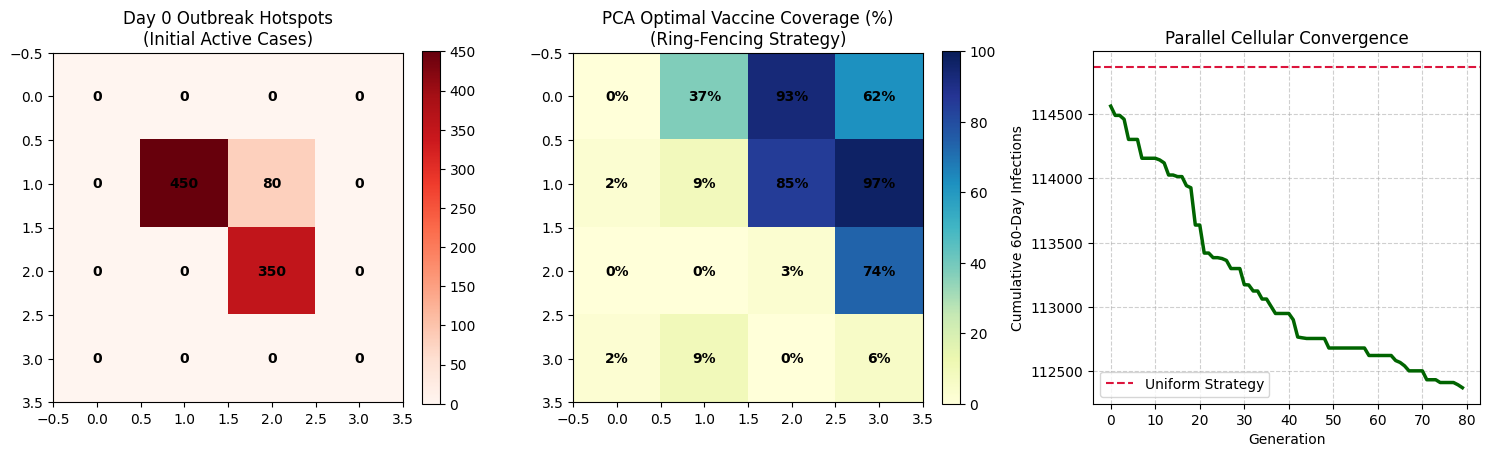

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1. CITY EPIDEMIOLOGY & VACCINE SUPPLY CONFIGURATION
# =========================================================
CITY_ROWS, CITY_COLS = 4, 4
NUM_DISTRICTS = CITY_ROWS * CITY_COLS  # 16 City Districts

# Population per district (10,000 citizens each)
POP_PER_DISTRICT = np.full(NUM_DISTRICTS, 10000.0)
TOTAL_POPULATION = np.sum(POP_PER_DISTRICT)

# Limited Vaccine Stockpile: Enough for only 30% of total city population
TOTAL_VACCINE_DOSES = 0.30 * TOTAL_POPULATION  # 48,000 doses

# Initial Active Infections per district (Two major outbreak hotspots)
INITIAL_INFECTED = np.zeros(NUM_DISTRICTS)
INITIAL_INFECTED[5] = 450.0   # Hotspot 1: Downtown Core (Row 1, Col 1)
INITIAL_INFECTED[10] = 350.0  # Hotspot 2: Industrial Hub (Row 2, Col 2)
INITIAL_INFECTED[6] = 80.0    # Early spillover district

# Epidemiological Parameters (60-day horizon)
BETA_LOCAL = 0.32      # Within-district transmission rate
BETA_NEIGHBOR = 0.08   # Cross-district commuter transmission rate
GAMMA = 0.10           # Recovery rate (10-day average infectious period)
VACCINE_EFFICACY = 0.90
SIM_DAYS = 60

# Precompute Spatial Adjacency Matrix between the 16 city districts
ADJACENCY = np.zeros((NUM_DISTRICTS, NUM_DISTRICTS))
for r in range(CITY_ROWS):
    for c in range(CITY_COLS):
        idx = r * CITY_COLS + c
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            nr, nc = r + dr, c + dc
            if 0 <= nr < CITY_ROWS and 0 <= nc < CITY_COLS:
                n_idx = nr * CITY_COLS + nc
                ADJACENCY[idx, n_idx] = 1.0

# =========================================================
# 2. PARALLEL CELLULAR ALGORITHM (PCA) HYPERPARAMETERS
# =========================================================
PCA_ROWS, PCA_COLS = 8, 8   # 64 parallel cells on a toroidal grid
MAX_GENERATIONS = 80
MUTATION_RATE = 0.15
MUTATION_STD = 0.08

# =========================================================
# 3. SPATIAL SIR EPIDEMIC SIMULATOR (FITNESS FUNCTION)
# =========================================================
def repair_allocation(alloc_vector):
    """
    Enforces bounds [0, 1] and scales allocation so total doses used
    never exceed TOTAL_VACCINE_DOSES.
    """
    alloc = np.clip(alloc_vector, 0.0, 1.0)
    doses_requested = np.sum(alloc * POP_PER_DISTRICT)
    if doses_requested > TOTAL_VACCINE_DOSES and doses_requested > 0:
        alloc *= (TOTAL_VACCINE_DOSES / doses_requested)
    return alloc

def simulate_epidemic(vaccine_allocation):
    """
    Runs a 60-day spatial SIR model across all 16 connected districts.
    Returns total cumulative infections across the entire city.
    """
    alloc = repair_allocation(vaccine_allocation)

    # Initial compartments
    I = INITIAL_INFECTED.copy()
    R = alloc * POP_PER_DISTRICT * VACCINE_EFFICACY  # Protected by vaccination
    S = np.maximum(0.0, POP_PER_DISTRICT - I - R)

    cumulative_infections = np.sum(I)

    for _ in range(SIM_DAYS):
        # Force of infection from local district + adjacent commuter districts
        local_force = BETA_LOCAL * (I / POP_PER_DISTRICT)
        neighbor_force = BETA_NEIGHBOR * (ADJACENCY @ (I / POP_PER_DISTRICT))

        new_infections = S * (local_force + neighbor_force)
        new_infections = np.minimum(S, new_infections)
        new_recoveries = GAMMA * I

        S -= new_infections
        I += new_infections - new_recoveries
        R += new_recoveries

        cumulative_infections += np.sum(new_infections)

    return cumulative_infections

# =========================================================
# 4. PARALLEL CELLULAR GENETIC ALGORITHM (cGA)
# =========================================================
def get_moore_neighbors(r, c):
    """Returns coordinates of the 8 Moore neighbors on a toroidal grid."""
    neighbors = []
    for dr in [-1, 0, 1]:
        for dc in [-1, 0, 1]:
            if dr == 0 and dc == 0:
                continue
            nr = (r + dr) % PCA_ROWS
            nc = (c + dc) % PCA_COLS
            neighbors.append((nr, nc))
    return neighbors

def run_parallel_cellular_optimization():
    np.random.seed(42)

    # Initialize 2D Toroidal Grid of candidate vaccine allocation vectors
    grid = np.random.uniform(0.0, 0.6, size=(PCA_ROWS, PCA_COLS, NUM_DISTRICTS))
    fitness_grid = np.zeros((PCA_ROWS, PCA_COLS))

    # Initial synchronous evaluation
    for r in range(PCA_ROWS):
        for c in range(PCA_COLS):
            grid[r, c] = repair_allocation(grid[r, c])
            fitness_grid[r, c] = simulate_epidemic(grid[r, c])

    best_history = []
    print("Running Parallel Cellular Optimization for COVID-19 Vaccine Allocation...\n")

    for gen in range(MAX_GENERATIONS):
        next_grid = np.copy(grid)
        next_fitness = np.copy(fitness_grid)

        # Synchronous Parallel Update across all grid cells
        for r in range(PCA_ROWS):
            for c in range(PCA_COLS):
                # 1. Inspect strictly local Moore neighborhood (8 surrounding cells)
                neighbors = get_moore_neighbors(r, c)
                best_n_coord = min(neighbors, key=lambda pos: fitness_grid[pos[0], pos[1]])
                local_leader = grid[best_n_coord[0], best_n_coord[1]]

                # 2. Local Uniform Crossover between cell (r, c) and its best neighbor
                mask = np.random.rand(NUM_DISTRICTS) < 0.5
                offspring = np.where(mask, grid[r, c], local_leader)

                # 3. Gaussian Mutation
                mut_mask = np.random.rand(NUM_DISTRICTS) < MUTATION_RATE
                offspring += mut_mask * np.random.normal(0.0, MUTATION_STD, size=NUM_DISTRICTS)
                offspring = repair_allocation(offspring)

                # 4. Greedy Local Replacement
                offspring_fit = simulate_epidemic(offspring)
                if offspring_fit < fitness_grid[r, c]:
                    next_grid[r, c] = offspring
                    next_fitness[r, c] = offspring_fit

        # Synchronous Grid Swap
        grid = next_grid
        fitness_grid = next_fitness

        current_best = np.min(fitness_grid)
        best_history.append(current_best)

        if (gen + 1) % 20 == 0 or gen == 0:
            print(f"Generation {gen+1:2d} | Lowest Projected City Infections: {current_best:,.0f}")

    best_idx = np.unravel_index(np.argmin(fitness_grid), fitness_grid.shape)
    return grid[best_idx], fitness_grid[best_idx], best_history

# =========================================================
# 5. EXECUTION, BENCHMARKING & VISUALIZATION
# =========================================================
# Baseline 1: No Vaccines
no_vaccine_infections = simulate_epidemic(np.zeros(NUM_DISTRICTS))

# Baseline 2: Uniform Allocation (30% coverage everywhere)
uniform_alloc = np.full(NUM_DISTRICTS, 0.30)
uniform_infections = simulate_epidemic(uniform_alloc)

# Optimized: Parallel Cellular Algorithm
optimal_alloc, opt_infections, history = run_parallel_cellular_optimization()

print("\n=====================================================================")
print("      COVID-19 VACCINE RESOURCE ALLOCATION OPTIMIZATION RESULTS      ")
print("=====================================================================")
print(f" Total City Population      : {TOTAL_POPULATION:,.0f} citizens")
print(f" Available Vaccine Stockpile: {TOTAL_VACCINE_DOSES:,.0f} doses (30.0% coverage)")
print("---------------------------------------------------------------------")
print(f" [Baseline 1] No Vaccination Strategy    : {no_vaccine_infections:,.0f} total infections")
print(f" [Baseline 2] Uniform Distribution (30%) : {uniform_infections:,.0f} total infections")
print(f" [Optimized ] Parallel Cellular Strategy : {opt_infections:,.0f} total infections")
print(f" Net Infections Averted vs. Uniform      : {uniform_infections - opt_infections:,.0f} cases saved!")
print("=====================================================================")

# Visualization: Heatmaps & Convergence
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Plot 1: Initial Outbreak Hotspots
im0 = axes[0].imshow(INITIAL_INFECTED.reshape(CITY_ROWS, CITY_COLS), cmap='Reds')
axes[0].set_title("Day 0 Outbreak Hotspots\n(Initial Active Cases)")
for r in range(CITY_ROWS):
    for c in range(CITY_COLS):
        val = int(INITIAL_INFECTED[r * CITY_COLS + c])
        axes[0].text(c, r, f"{val}", ha='center', va='center', color='black', fontweight='bold')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# Plot 2: PCA Optimal Vaccine Allocation Heatmap (%)
alloc_grid = (optimal_alloc * 100).reshape(CITY_ROWS, CITY_COLS)
im1 = axes[1].imshow(alloc_grid, cmap='YlGnBu', vmin=0, vmax=100)
axes[1].set_title("PCA Optimal Vaccine Coverage (%)\n(Ring-Fencing Strategy)")
for r in range(CITY_ROWS):
    for c in range(CITY_COLS):
        axes[1].text(c, r, f"{alloc_grid[r, c]:.0f}%", ha='center', va='center', color='black', fontweight='bold')
plt.colorbar(im1, ax=axes[1], fraction=0.046)

# Plot 3: Convergence Curve
axes[2].plot(history, color='darkgreen', linewidth=2.5)
axes[2].axhline(uniform_infections, color='crimson', linestyle='--', label='Uniform Strategy')
axes[2].set_title("Parallel Cellular Convergence")
axes[2].set_xlabel("Generation")
axes[2].set_ylabel("Cumulative 60-Day Infections")
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()